In [1]:
#### follow the notebook for analysis of 1 subband effective model 

In [2]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
from Minimal_Model_2D import *
import Minimal_model_1D_1sub as M_1sub
import Minimal_Model_1D as M1
import time

np.set_printoptions(threshold=sys.maxsize)

In [3]:
NSM = 60          # in nm
MY = 4             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

print("MU =", MU_SC)

ALPHAT = np.linspace(1, 50, 81)

K = 8

first subband energy = 1.3263440267269595 
 second subband energy = 2.652688053453919
first subband= 0.6631720133634798 second subband = 1.9895160400904393
MU = 1.4631720133634798


In [4]:
Ep_li_1d_many_subbands = np.load("1d_model_linear_SpinSplitting.npy")

In [5]:
Ep_li_1deff = np.load("1d_1subeff_model_linear_SpinSplitting.npy")

In [6]:
Ep_li_2d = np.load("2d_model_linear_SpinSplitting.npy")

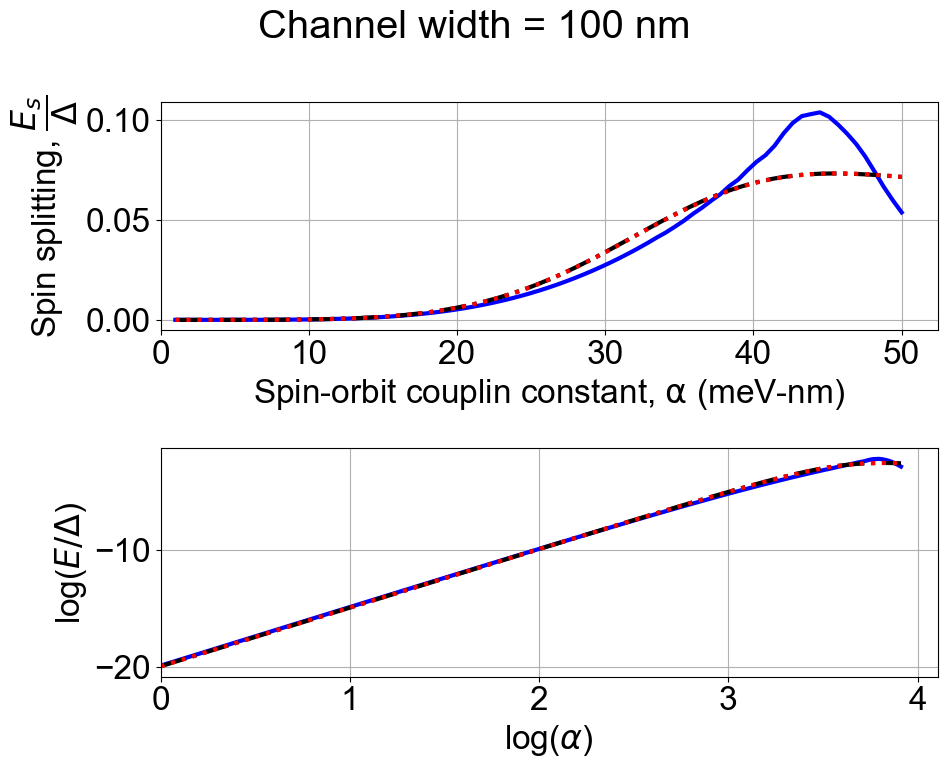

In [12]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

Ep_Split_li_1d = (Ep_li_1d_many_subbands[:,K//2+1] - Ep_li_1d_many_subbands[:,K//2])
Ep_Split_li_1deff = (Ep_li_1deff[:,K//2+1] - Ep_li_1deff[:,K//2])
Ep_Split_li_2d = (Ep_li_2d[:,K//2+1] - Ep_li_2d[:,K//2])


plt.subplot(2,1,1)
plt.plot((ALPHAT), (Ep_Split_li_1deff/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot((ALPHAT), (Ep_Split_li_2d/DELTA), lw=3 ,linestyle ='-.' , color='black', label= '2d model')
plt.plot((ALPHAT), (Ep_Split_li_1d/DELTA), lw=3 ,linestyle =':' , color='red', label= '1d model with few(4) subbands')

plt.xlabel(r'Spin-orbit couplin constant, $\mathrm{\alpha}$ (meV-nm)')
plt.ylabel(r'Spin splitting, $\dfrac{E_{s}}{\mathrm{\Delta}}$')
plt.grid(True)
plt.xlim(left=0)

plt.subplot(2,1,2)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li_1deff/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li_2d/DELTA), lw=3 ,linestyle ='-.' , color='black', label=  '2d model')
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li_1d/DELTA), lw=3 ,linestyle =':' , color='red', label='1d model with few(4) subbands')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.xlim(left=0)
plt.grid(True)

plt.suptitle('Channel width = %i nm' %LY)

plt.tight_layout()

#plt.legend()

plt.show()

In [19]:
X = np.log(ALPHAT)

Y2 = np.log(Ep_Split_li_1deff/DELTA)

Y = (X-X[0])*5 + Y2[0]

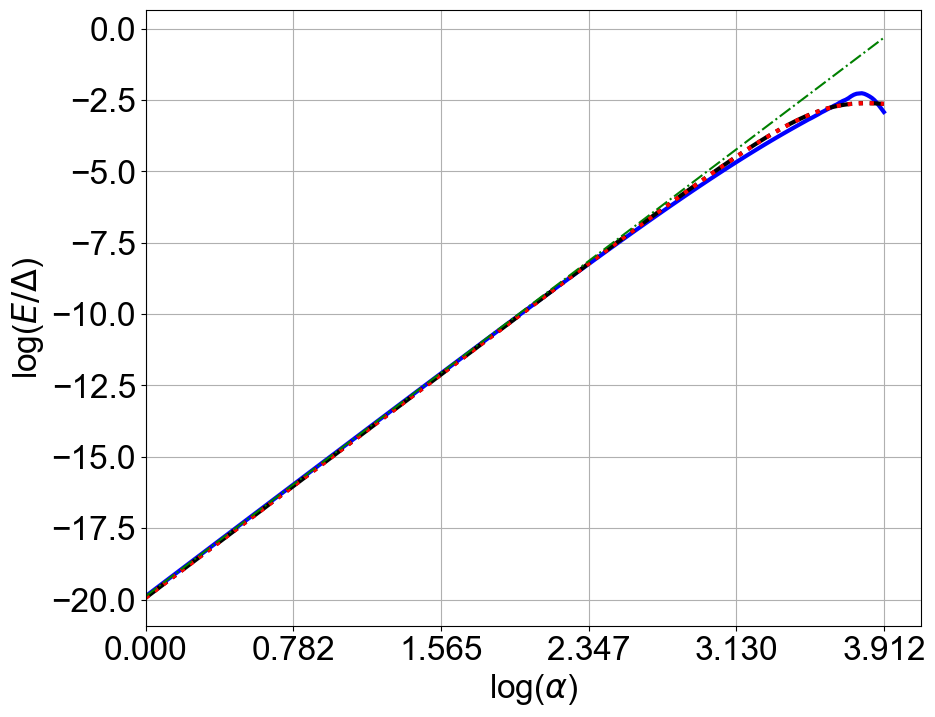

In [31]:
f = plt.figure(figsize=(10, 8))

plt.plot(np.log(ALPHAT), np.log(Ep_Split_li_1deff/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li_2d/DELTA), lw=3 ,linestyle ='-.' , color='black', label=  '2d model')
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li_1d/DELTA), lw=3 ,linestyle =':' , color='red', label='1d model with few(4) subbands')
plt.plot(X,Y, linestyle= '-.' ,color='green')
plt.xticks(np.linspace(min(X), max(X), 6))
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.xlim(left=0)
plt.grid(True)


In [100]:
X = ALPHAT

Y2 = Ep_Split_li_1deff/DELTA

Y = (X-X[1])*5 + Y2[1]

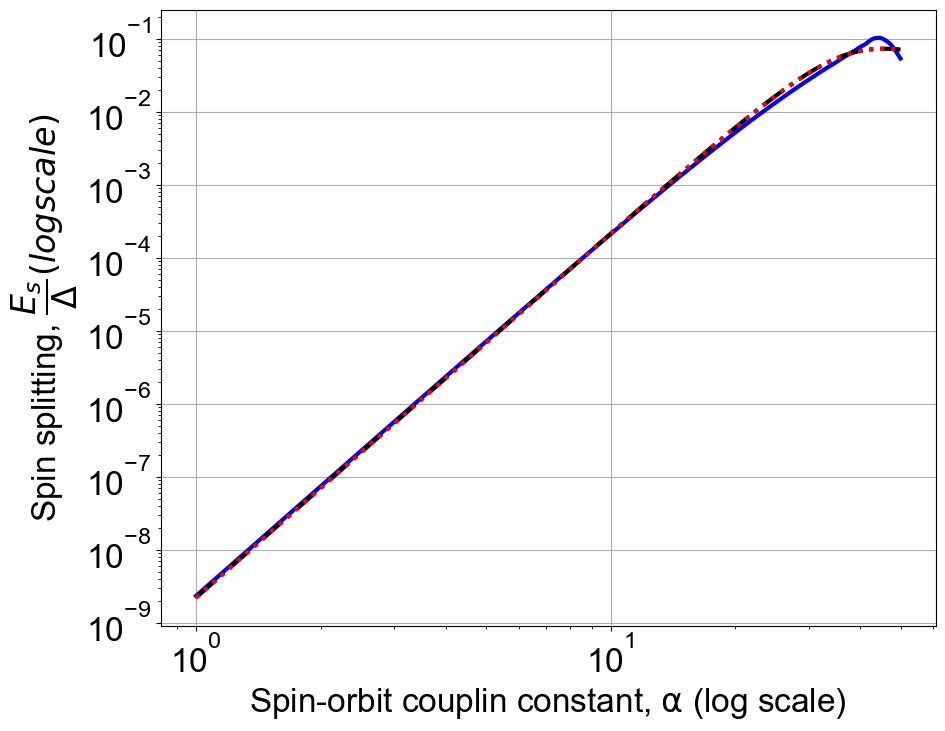

In [102]:
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

plt.plot((ALPHAT), (Ep_Split_li_1deff/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot((ALPHAT), (Ep_Split_li_2d/DELTA), lw=3 ,linestyle ='-.' , color='black', label= '2d model')
plt.plot((ALPHAT), (Ep_Split_li_1d/DELTA), lw=3 ,linestyle =':' , color='red', label= '1d model with few(4) subbands')
 #plt.plot(X, Y, lw=3, linestyle= '-.' ,color='green')

plt.xscale('log')
plt.yscale('log')

plt.xlabel(r'Spin-orbit couplin constant, $\mathrm{\alpha}$ (log scale)')
plt.ylabel(r'Spin splitting, $\dfrac{E_{s}}{\mathrm{\Delta}} (log scale)$')
plt.grid(True)
#plt.xlim(left=0)


In [32]:
math.exp(2.334)

10.319135632448981

In [29]:
math.exp(3.1)

22.197951281441636

In [34]:
22.19**5

5380052.469160711

[20 30 40 45 50]


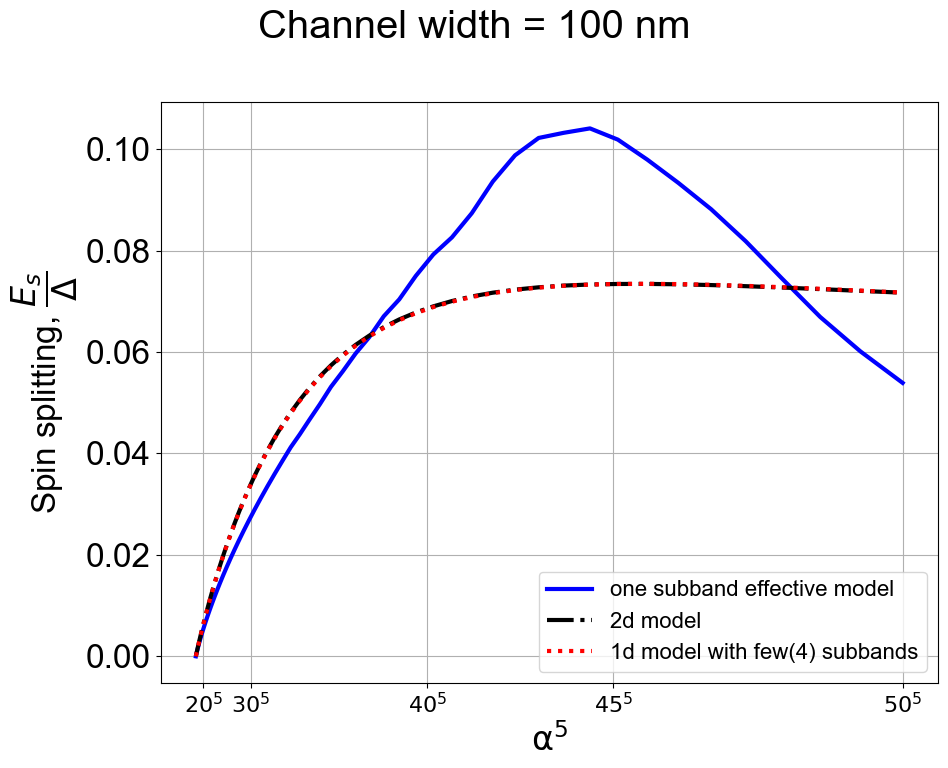

In [135]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

Ep_Split_li_1d = (Ep_li_1d_many_subbands[:,K//2+1] - Ep_li_1d_many_subbands[:,K//2])
Ep_Split_li_1deff = (Ep_li_1deff[:,K//2+1] - Ep_li_1deff[:,K//2])
Ep_Split_li_2d = (Ep_li_2d[:,K//2+1] - Ep_li_2d[:,K//2])


#X = ALPHAT

#Y2 = Ep_Split_li_1deff/DELTA

#Y = (X-X[0])*(Y2[1]-Y2[0])/(X[1]-X[0]) + Y2[0]
#SLOPE= (Y2[1]-Y2[0])/(X[1]-X[0])

#Y = (X-X[0])*SLOPE + Y2[0]
#Y = SLOPE*X

#Ynew = (X-X[0])*(Y2[1]-Y2[0])/(X[1]-X[0]) + Y2[0]

plt.subplot(1,1,1)
plt.plot(ALPHAT**5, Ep_Split_li_1deff/DELTA, lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot(ALPHAT**5, Ep_Split_li_2d/DELTA, lw=3 ,linestyle ='-.' , color='black', label=  '2d model')
plt.plot(ALPHAT**5, Ep_Split_li_1d/DELTA, lw=3 ,linestyle =':' , color='red', label='1d model with few(4) subbands')
#plt.plot(X, Y, lw=3 ,linestyle ='-' , color='green')
plt.xlabel(r'$\mathrm{\alpha^5}$', fontsize=24)
plt.ylabel(r'Spin splitting, $\dfrac{E_{s}}{\mathrm{\Delta}}$')

X_TICKS = np.array([ 20, 30, 40, 45, 50])
print(X_TICKS)

# Manually set the x-axis ticks and labels
plt.xticks(X_TICKS**5, [f'${{{round(a)}}}^5$' for a in X_TICKS],fontsize=16)

#plt.xlim(left=0, right=22.19**5)
#plt.ylim(bottom=0, top=0.012)
plt.grid(True)

plt.suptitle('Channel width = %i nm' %LY)

plt.tight_layout()

plt.legend(fontsize=16)

plt.show()

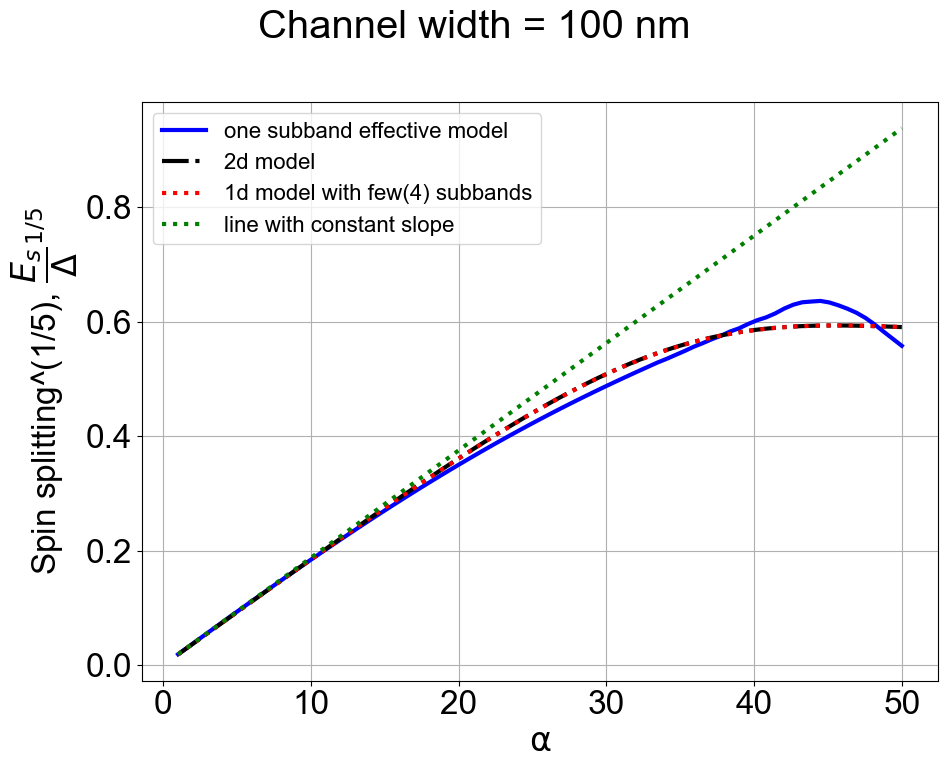

In [146]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

Ep_Split_li_1d = (Ep_li_1d_many_subbands[:,K//2+1] - Ep_li_1d_many_subbands[:,K//2])
Ep_Split_li_1deff = (Ep_li_1deff[:,K//2+1] - Ep_li_1deff[:,K//2])
Ep_Split_li_2d = (Ep_li_2d[:,K//2+1] - Ep_li_2d[:,K//2])


X = ALPHAT

Y2 = (Ep_Split_li_1deff/DELTA)**(0.2)

Y = (X-X[0])*(Y2[1]-Y2[0])/(X[1]-X[0]) + Y2[0]
SLOPE= (Y2[1]-Y2[0])/(X[1]-X[0])

#Y = (X-X[0])*SLOPE + Y2[0]
#Y = SLOPE*X

#Ynew = (X-X[0])*(Y2[1]-Y2[0])/(X[1]-X[0]) + Y2[0]

plt.subplot(1,1,1)
plt.plot(ALPHAT, (Ep_Split_li_1deff/DELTA)**(0.2), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot(ALPHAT, (Ep_Split_li_2d/DELTA)**(0.2), lw=3 ,linestyle ='-.' , color='black', label=  '2d model')
plt.plot(ALPHAT, (Ep_Split_li_1d/DELTA)**(0.2), lw=3 ,linestyle =':' , color='red', label='1d model with few(4) subbands')
plt.plot(X, Y, lw=3 ,linestyle =':' , color='green', label='line with constant slope')
plt.xlabel(r'$\mathrm{\alpha}$', fontsize=24)
plt.ylabel(r'Spin splitting^(1/5), ${\dfrac{E_{s}}{\mathrm{\Delta}}^{1/5}}$')

#X_TICKS = np.array([ 20, 30, 40, 45, 50])
#print(X_TICKS)

# Manually set the x-axis ticks and labels
#plt.xticks(X_TICKS**5, [f'${{{round(a)}}}^5$' for a in X_TICKS],fontsize=16)

#plt.xlim(left=0, right=22.19**5)
#plt.ylim(bottom=0, top=0.012)
plt.grid(True)

plt.suptitle('Channel width = %i nm' %LY)

plt.tight_layout()

plt.legend(fontsize=16)

plt.show()

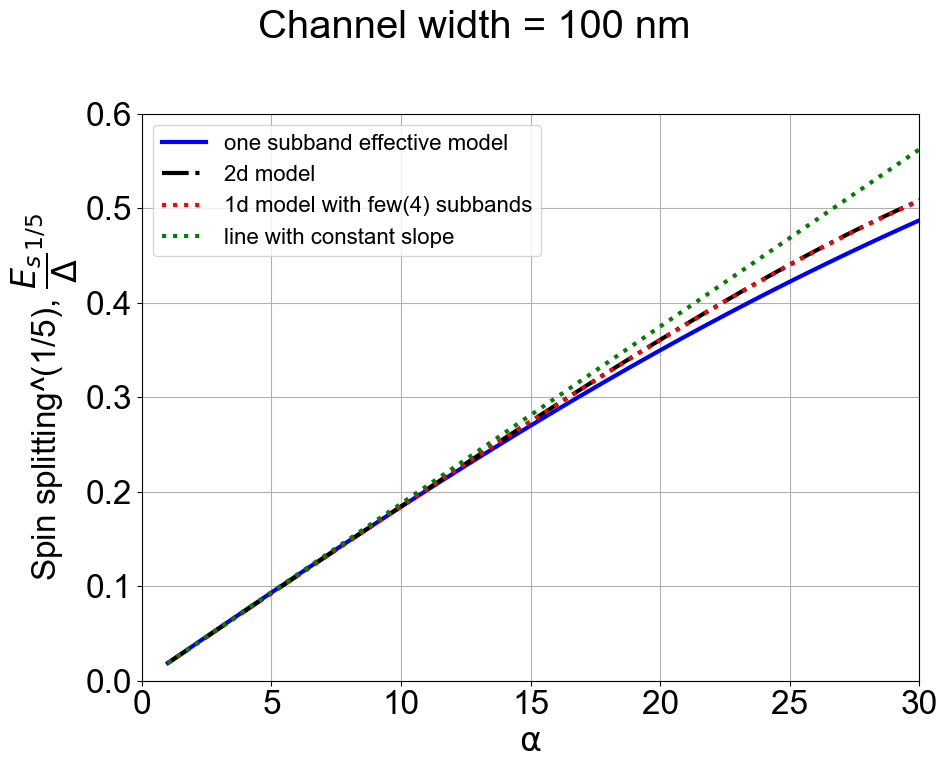

In [148]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

Ep_Split_li_1d = (Ep_li_1d_many_subbands[:,K//2+1] - Ep_li_1d_many_subbands[:,K//2])
Ep_Split_li_1deff = (Ep_li_1deff[:,K//2+1] - Ep_li_1deff[:,K//2])
Ep_Split_li_2d = (Ep_li_2d[:,K//2+1] - Ep_li_2d[:,K//2])


X = ALPHAT

Y2 = (Ep_Split_li_1deff/DELTA)**(0.2)

Y = (X-X[0])*(Y2[1]-Y2[0])/(X[1]-X[0]) + Y2[0]
SLOPE= (Y2[1]-Y2[0])/(X[1]-X[0])

#Y = (X-X[0])*SLOPE + Y2[0]
#Y = SLOPE*X

#Ynew = (X-X[0])*(Y2[1]-Y2[0])/(X[1]-X[0]) + Y2[0]

plt.subplot(1,1,1)
plt.plot(ALPHAT, (Ep_Split_li_1deff/DELTA)**(0.2), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot(ALPHAT, (Ep_Split_li_2d/DELTA)**(0.2), lw=3 ,linestyle ='-.' , color='black', label=  '2d model')
plt.plot(ALPHAT, (Ep_Split_li_1d/DELTA)**(0.2), lw=3 ,linestyle =':' , color='red', label='1d model with few(4) subbands')
plt.plot(X, Y, lw=3 ,linestyle =':' , color='green', label='line with constant slope')
plt.xlabel(r'$\mathrm{\alpha}$', fontsize=24)
plt.ylabel(r'Spin splitting^(1/5), ${\dfrac{E_{s}}{\mathrm{\Delta}}^{1/5}}$')

#X_TICKS = np.array([ 20, 30, 40, 45, 50])
#print(X_TICKS)

# Manually set the x-axis ticks and labels
#plt.xticks(X_TICKS**5, [f'${{{round(a)}}}^5$' for a in X_TICKS],fontsize=16)

plt.xlim(left=0, right=30)
plt.ylim(bottom=0, top=0.6)
plt.grid(True)

plt.suptitle('Channel width = %i nm' %LY)

plt.tight_layout()

plt.legend(fontsize=16)

plt.show()

[10 15 18 20]


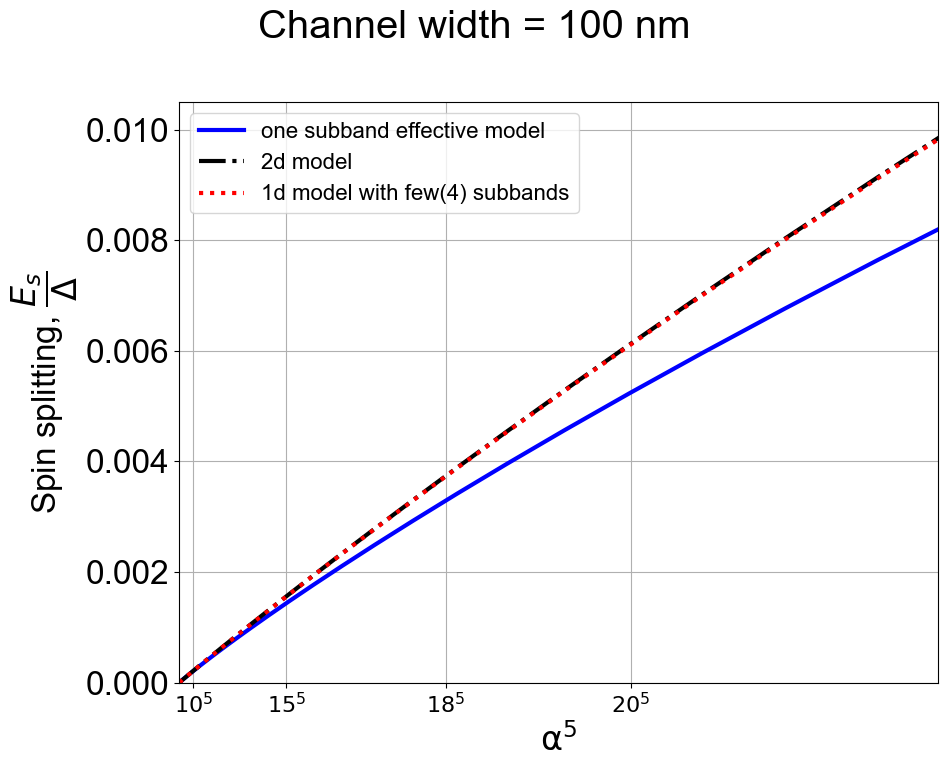

In [134]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

Ep_Split_li_1d = (Ep_li_1d_many_subbands[:,K//2+1] - Ep_li_1d_many_subbands[:,K//2])
Ep_Split_li_1deff = (Ep_li_1deff[:,K//2+1] - Ep_li_1deff[:,K//2])
Ep_Split_li_2d = (Ep_li_2d[:,K//2+1] - Ep_li_2d[:,K//2])



#X = ALPHAT**5
#Y2 = Ep_Split_li_1deff/DELTA
#Y = (X-X[0])*(Y2[1]-Y2[0])/(X[1]-X[0]) + Y2[0]
#SLOPE= (Y2[1]-Y2[0])/(X[1]-X[0])

#Y = (X-X[0])*SLOPE + Y2[0]
#Y = SLOPE*X

#Ynew = (X-X[0])*(Y2[1]-Y2[0])/(X[1]-X[0]) + Y2[0]

plt.subplot(1,1,1)
plt.plot(ALPHAT**5, Ep_Split_li_1deff/DELTA, lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot(ALPHAT**5, Ep_Split_li_2d/DELTA, lw=3 ,linestyle ='-.' , color='black', label=  '2d model')
plt.plot(ALPHAT**5, Ep_Split_li_1d/DELTA, lw=3 ,linestyle =':' , color='red', label='1d model with few(4) subbands')
#plt.plot(X, Y, lw=3 ,linestyle =':' , color='green', label='line with constant slope {}'.format(SLOPE))
plt.xlabel(r'$\mathrm{\alpha^5}$', fontsize=24)
plt.ylabel(r'Spin splitting, $\dfrac{E_{s}}{\mathrm{\Delta}}$')

X_TICKS = np.array([ 10, 15, 18, 20])
print(X_TICKS)

# Manually set the x-axis ticks and labels
plt.xticks(X_TICKS**5, [f'${{{round(a)}}}^5$' for a in X_TICKS],fontsize=16)

plt.xlim(left=0, right=22.19**5)
plt.ylim(bottom=0, top=0.0105)
plt.grid(True)

plt.suptitle('Channel width = %i nm' %LY)

plt.tight_layout()

plt.legend(fontsize=16)

plt.show()

[10 15 18 20]


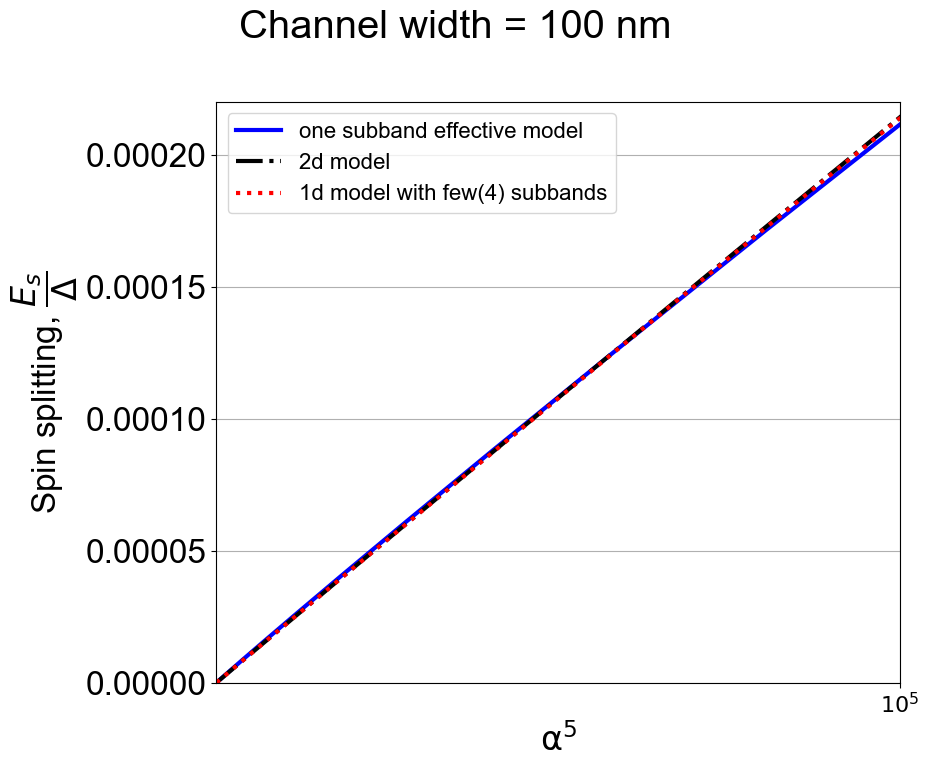

In [153]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

Ep_Split_li_1d = (Ep_li_1d_many_subbands[:,K//2+1] - Ep_li_1d_many_subbands[:,K//2])
Ep_Split_li_1deff = (Ep_li_1deff[:,K//2+1] - Ep_li_1deff[:,K//2])
Ep_Split_li_2d = (Ep_li_2d[:,K//2+1] - Ep_li_2d[:,K//2])



#X = ALPHAT**5
#Y2 = Ep_Split_li_1deff/DELTA
#Y = (X-X[0])*(Y2[1]-Y2[0])/(X[1]-X[0]) + Y2[0]
#SLOPE= (Y2[1]-Y2[0])/(X[1]-X[0])

#Y = (X-X[0])*SLOPE + Y2[0]
#Y = SLOPE*X

#Ynew = (X-X[0])*(Y2[1]-Y2[0])/(X[1]-X[0]) + Y2[0]

plt.subplot(1,1,1)
plt.plot(ALPHAT**5, Ep_Split_li_1deff/DELTA, lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot(ALPHAT**5, Ep_Split_li_2d/DELTA, lw=3 ,linestyle ='-.' , color='black', label=  '2d model')
plt.plot(ALPHAT**5, Ep_Split_li_1d/DELTA, lw=3 ,linestyle =':' , color='red', label='1d model with few(4) subbands')
#plt.plot(X, Y, lw=3 ,linestyle =':' , color='green', label='line with constant slope {}'.format(SLOPE))
plt.xlabel(r'$\mathrm{\alpha^5}$', fontsize=24)
plt.ylabel(r'Spin splitting, $\dfrac{E_{s}}{\mathrm{\Delta}}$')

X_TICKS = np.array([ 10, 15, 18, 20])
print(X_TICKS)

# Manually set the x-axis ticks and labels
plt.xticks(X_TICKS**5, [f'${{{round(a)}}}^5$' for a in X_TICKS],fontsize=16)

#plt.xlim(left=0, right=15**5)
#plt.ylim(bottom=0, top=0.0016)

plt.xlim(left=0, right=10**5)
plt.ylim(bottom=0, top=0.00022)

plt.grid(True)

plt.suptitle('Channel width = %i nm' %LY)

plt.tight_layout()

plt.legend(fontsize=16)

plt.show()

In [152]:
print(Ep_Split_li_2d/Ep_Split_li_1deff)

[0.94654539 0.9476769  0.94933296 0.95151079 0.95420466 0.95740765
 0.96111152 0.96530678 0.96998272 0.97512746 0.98072798 0.98677015
 0.99323874 1.00011744 1.00738885 1.01503448 1.02303472 1.03136881
 1.04001487 1.04894982 1.05814944 1.06758831 1.07723975 1.08707559
 1.09706567 1.10717706 1.11737292 1.12761129 1.13784426 1.14801795
 1.15807401 1.16795238 1.17759446 1.18694462 1.19594736 1.20453894
 1.21263584 1.220127   1.22687774 1.23274823 1.23761902 1.24140688
 1.24405477 1.24549616 1.24561953 1.24426759 1.24127889 1.23653599
 1.22997215 1.22152898 1.21112027 1.1986595  1.18412265 1.16646833
 1.15444003 1.13364954 1.11053175 1.07984063 1.05749353 1.02842546
 1.00488628 0.96790999 0.9438075  0.90395046 0.87092517 0.84798317
 0.81210427 0.7659511  0.73189069 0.71189294 0.70818918 0.70429646
 0.72065553 0.74982615 0.78586207 0.83034646 0.89162808 0.9760891
 1.08203897 1.19844554 1.32991764]


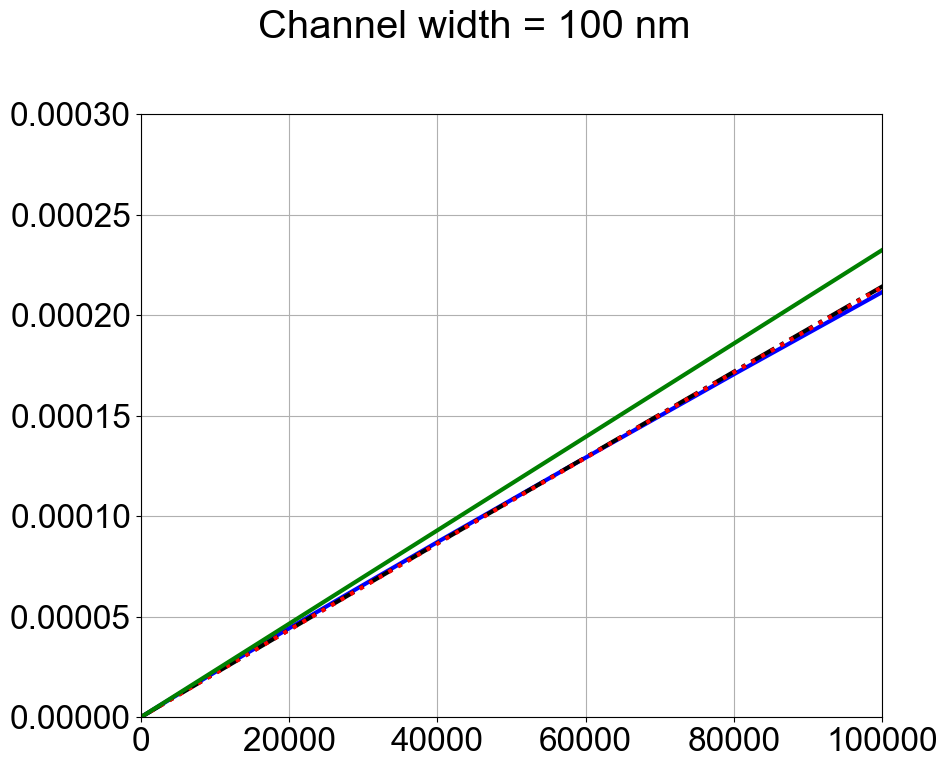

In [89]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

Ep_Split_li_1d = (Ep_li_1d_many_subbands[:,K//2+1] - Ep_li_1d_many_subbands[:,K//2])
Ep_Split_li_1deff = (Ep_li_1deff[:,K//2+1] - Ep_li_1deff[:,K//2])
Ep_Split_li_2d = (Ep_li_2d[:,K//2+1] - Ep_li_2d[:,K//2])


X = ALPHAT**5

Y2 = Ep_Split_li_1deff/DELTA

Y = (X-X[0])*(Y2[1]-Y2[0])/(X[1]-X[0]) + Y2[0]
#SLOPE= (Y2[1]-Y2[0])/(X[1]-X[0])

#Y = (X-X[0])*SLOPE + Y2[0]
#Y = SLOPE*X

#Ynew = (X-X[0])*(Y2[1]-Y2[0])/(X[1]-X[0]) + Y2[0]

plt.subplot(1,1,1)
plt.plot(ALPHAT**5, Ep_Split_li_1deff/DELTA, lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot(ALPHAT**5, Ep_Split_li_2d/DELTA, lw=3 ,linestyle ='-.' , color='black', label=  '2d model')
plt.plot(ALPHAT**5, Ep_Split_li_1d/DELTA, lw=3 ,linestyle =':' , color='red', label='1d model with few(4) subbands')
plt.plot(X, Y, lw=3 ,linestyle ='-' , color='green')
#plt.xlabel(r'log($\alpha$)', fontsize=24)
#plt.ylabel(r'log($E/\Delta$)', fontsize=24)
# Set both axes to a log scale
#plt.xscale('log', base=2)
#plt.yscale('log')
#plt.xlim(left=0, right=22.19**5)
plt.xlim(left=0, right=10**5)
plt.ylim(bottom=0, top=0.0003)
plt.grid(True)

plt.suptitle('Channel width = %i nm' %LY)

plt.tight_layout()

#plt.legend()

plt.show()

In [56]:
math.exp(4)

54.598150033144236

In [44]:
print(X,Y)

[1.00000000e+00 1.09018102e+01 5.45318306e+01 1.83941342e+02
 4.88759797e+02 1.10653937e+03 2.23309951e+03 4.13287150e+03
 7.14924299e+03 1.17149026e+04 1.83621844e+04 2.77334124e+04
 4.05912455e+04 5.78290214e+04 8.04811018e+04 1.09733216e+05
 1.46932808e+05 1.93599376e+05 2.51434823e+05 3.22333796e+05
 4.08394036e+05 5.11926717e+05 6.35466795e+05 7.81783348e+05
 9.53889926e+05 1.15505489e+06 1.38881176e+06 1.65896957e+06
 1.96962318e+06 2.32516366e+06 2.73028860e+06 3.19001249e+06
 3.70967704e+06 4.29496151e+06 4.95189311e+06 5.68685729e+06
 6.50660809e+06 7.41827852e+06 8.42939088e+06 9.54786710e+06
 1.07820391e+07 1.21406591e+07 1.36329101e+07 1.52684159e+07
 1.70572518e+07 1.90099549e+07 2.11375342e+07 2.34514811e+07
 2.59637799e+07 2.86869176e+07 3.16338952e+07 3.48182369e+07
 3.82540014e+07 4.19557917e+07 4.59387657e+07 5.02186464e+07
 5.48117322e+07 5.97349074e+07 6.50056527e+07 7.06420549e+07
 7.66628181e+07 8.30872734e+07 8.99353894e+07 9.72277827e+07
 1.04985728e+08 1.132311